# Instance Segmentation with 3 Models / 3 Architecture Families


| # | Model | Architecture family | Key idea |
|---|-------|---------------------|----------|
| 1 | **YOLO11n-seg** (Ultralytics) | One-stage, anchor-free CNN detector + ProtoNet mask branch | Dense single-shot prediction, no proposals, NMS at inference |
| 2 | **Mask R-CNN** (ResNet-50-FPN, torchvision) | Two-stage region-based CNN (RPN -> RoIAlign -> per-ROI mask head) | Proposal generation + ROI-aligned features |
| 3 | **Mask2Former** (Swin-Tiny, Hugging Face Transformers) | Transformer, query-based masked attention + Hungarian matching | Set prediction, no anchors / no NMS |

```
<class_index> <x1> <y1> <x2> <y2> ... <xN> <yN>     # normalized 0..1 polygon (>= 3 points)
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Environment

Installs only what is missing. After an install, restart the kernel and run again
(the import cells at the top must succeed).

In [2]:
import importlib.util, subprocess, sys
import contextlib, gc, io, json, math, os, random, shutil, time, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from collections import Counter, defaultdict
from pathlib import Path

import cv2
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, Dataset
import albumentations as A

from ultralytics import YOLO

from torchvision.models.detection import MaskRCNN_ResNet50_FPN_V2_Weights, maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation, Mask2FormerImageProcessor

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import pycocotools.mask as mask_utils

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42


def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Keep cudnn.benchmark=False: Mask R-CNN / Mask2Former have dynamic RoI/instance counts per batch,
    # which makes cuDNN re-autotune on almost every iteration (5-15x slowdown).
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.set_float32_matmul_precision("high")


seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
# Native bf16 Tensor Cores require Ampere+ (CC >= 8.0); T4 (CC 7.5) is faster with fp16 + GradScaler.
USE_BF16 = (
    DEVICE.type == "cuda"
    and torch.cuda.get_device_capability(0)[0] >= 8
    and torch.cuda.is_bf16_supported()
)

print(f"python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"device      : {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    cc = torch.cuda.get_device_capability(0)
    print(f"gpu         : {props.name} ({GPU_VRAM_GB:.1f} GB, CC {cc[0]}.{cc[1]})")
    amp_label = "bfloat16" if USE_BF16 else "float16"
    print(f"amp dtype   : {amp_label}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
python      : 3.13.16
torch       : 2.14.1+cu130
torchvision : 0.29.1+cu130
device      : cuda
gpu         : NVIDIA L4 (23.7 GB, CC 8.9)
amp dtype   : bfloat16


## 1. Configuration

Everything that you normally want to change lives here.

In [3]:
PROJECT_DIR = Path.cwd().resolve()

# --- input data ---------------------------------------------------------------
# A pre-split YOLO dataset folder (Roboflow / Ultralytics "seg" or "obb" export):
#   <root>/data.yaml
#   <root>/train/images  <root>/train/labels
#   <root>/valid/images  <root>/valid/labels     # "val" is accepted too
#   <root>/test/images   <root>/test/labels      # optional
# Both "valid" and "val" are accepted; "test" is optional.
DATASET_ROOT = Path("/content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb")
if not DATASET_ROOT.is_dir():
    # Fallback to current directory check if Google Drive path is not mounted or wrong
    DATASET_ROOT = PROJECT_DIR / "panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb"
if not DATASET_ROOT.is_dir():
    DATASET_ROOT = None       # None -> auto-detect a train/ folder under PROJECT_DIR

# --- dataset / preprocessing --------------------------------------------------
CLASS_NAMES = None          # e.g. ["pot", "pan", "spoon"]; None = read data.yaml / infer
IMG_SIZE = 512              # every model trains and is evaluated at 512x512
RESIZE_MODE = "pad"         # "pad" = letterbox (keeps aspect ratio) | "stretch"
DS_DIRNAME = "dataset_512"
EVAL_SPLIT = "val"          # "val" while iterating, "test" for the final held-out score

# --- training ----------------------------------------------------------------
FAST_DEV_RUN = False        # True: subset of images + 2 epochs, for a pipeline check
MAX_IMAGES = None           # cap the number of images per split (None = all)
import multiprocessing as _mp

EPOCHS = {"yolo": 100, "maskrcnn": 50, "mask2former": 25}
if GPU_VRAM_GB >= 12.0:
    BATCH_SIZE = {"yolo": 64, "maskrcnn": 16, "mask2former": 4}
    LR = {"maskrcnn": 0.015, "mask2former": 2e-4}
else:
    BATCH_SIZE = {"yolo": 16, "maskrcnn": 4, "mask2former": 4}
    LR = {"maskrcnn": 0.005, "mask2former": 1e-4}

# Use multi-worker prefetching on Linux fork (Colab); fall back to 0 on Windows / Python 3.14+ forkserver.
_can_fork = (
    os.name == "posix"
    and sys.version_info < (3, 14)
    and _mp.get_start_method(allow_none=True) in (None, "fork")
)
NUM_WORKERS = min(8, os.cpu_count() or 2) if _can_fork else 0
AUG_LEVEL = "aug 2"  # Options: "no aug", "aug 1", "aug 2"

if FAST_DEV_RUN:
    MAX_IMAGES = MAX_IMAGES or 10
    EPOCHS = {k: 2 for k in EPOCHS}

OUT_DIR = PROJECT_DIR / "outputs"
for d in (OUT_DIR,):
    d.mkdir(parents=True, exist_ok=True)

print(json.dumps({
    "project_dir": str(PROJECT_DIR), "dataset_root": str(DATASET_ROOT),
    "img_size": IMG_SIZE, "resize_mode": RESIZE_MODE, "eval_split": EVAL_SPLIT,
    "fast_dev_run": FAST_DEV_RUN, "epochs": EPOCHS,
    "batch_size": BATCH_SIZE, "lr": LR, "num_workers": NUM_WORKERS,
}, indent=2))

{
  "project_dir": "/content",
  "dataset_root": "/content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb",
  "img_size": 512,
  "resize_mode": "pad",
  "eval_split": "val",
  "fast_dev_run": false,
  "epochs": {
    "yolo": 100,
    "maskrcnn": 50,
    "mask2former": 25
  },
  "batch_size": {
    "yolo": 64,
    "maskrcnn": 16,
    "mask2former": 4
  },
  "lr": {
    "maskrcnn": 0.015,
    "mask2former": 0.0002
  },
  "num_workers": 8
}


## 2. Dataset Loader & Preprocessing (Self-Contained)

The input is a pre-split YOLO dataset folder (e.g., `panoptic-indoor-segmentation...yolov8-obb`):

```
<dataset_root>/
  data.yaml
  train/images    train/labels
  valid/images    valid/labels      # "val" is accepted too
  test/images     test/labels       # optional
```

Everything for discovering splits, parsing polygon/OBB/bbox labels, letterboxing to `IMG_SIZE`, writing `data.yaml` + COCO JSON annotations, and loading tensors into PyTorch (`YoloSegDataset`) is defined directly below inside the notebook (no external `.py` loader needed).

In [4]:
import yaml
from dataclasses import dataclass, field

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {"train": ("train",), "val": ("valid", "val"), "test": ("test",)}


def parse_label_line(line: str):
    parts = line.split()
    if len(parts) < 5:
        return None
    try:
        cls = int(float(parts[0]))
        vals = np.asarray([float(v) for v in parts[1:]], dtype=np.float32)
    except ValueError:
        return None
    if vals.size < 4 or vals.size % 2 != 0:
        return None
    if vals.size == 4:
        cx, cy, w, h = vals
        poly = np.array([[cx - w / 2, cy - h / 2], [cx + w / 2, cy - h / 2],
                         [cx + w / 2, cy + h / 2], [cx - w / 2, cy + h / 2]], dtype=np.float32)
        return cls, poly, "bbox"
    return cls, vals.reshape(-1, 2), "polygon"


def read_labels(path, width: int, height: int):
    if path is None or not Path(path).is_file():
        return []
    out = []
    for raw in Path(path).read_text().splitlines():
        parsed = parse_label_line(raw) if raw.strip() else None
        if parsed is None:
            continue
        cls, poly, kind = parsed
        if poly.max() > 1.5:
            poly = poly / np.array([width, height], dtype=np.float32)
        poly = np.clip(poly, 0.0, 1.0) * np.array([width, height], dtype=np.float32)
        if kind == "polygon" and cv2.contourArea(poly) < 4:
            continue
        out.append({"cls": cls, "poly": poly, "kind": kind})
    return out


def letterbox_and_scale(im: Image.Image, polys_px, size: int, mode: str = "pad", pad_value: int = 114):
    W, H = im.size
    if mode == "stretch":
        return im.resize((size, size), Image.BILINEAR), [p * np.array([size / W, size / H], np.float32) for p in polys_px]
    ratio = min(size / W, size / H)
    nw, nh = max(1, int(round(W * ratio))), max(1, int(round(H * ratio)))
    dx, dy = (size - nw) // 2, (size - nh) // 2
    out = Image.new("RGB", (size, size), (pad_value,) * 3)
    out.paste(im.resize((nw, nh), Image.BILINEAR), (dx, dy))
    return out, [p * ratio + np.array([dx, dy], np.float32) for p in polys_px]


@dataclass
class SplitPaths:
    name: str
    images_dir: Path
    labels_dir: Path | None
    image_paths: list[Path] = field(default_factory=list)
    missing_labels: list[Path] = field(default_factory=list)

    def label_for(self, image: Path) -> Path | None:
        cands = []
        if self.labels_dir is not None:
            cands.append(self.labels_dir / f"{image.stem}.txt")
        cands.append(image.with_suffix(".txt"))
        return next((c for c in cands if c.is_file()), None)


@dataclass
class DatasetSpec:
    root: Path
    splits: dict[str, SplitPaths]
    class_names: list[str]
    yaml_path: Path | None = None


@dataclass
class PreparedDataset:
    root: Path
    yaml_path: Path
    class_names: list[str]
    img_size: int
    images: dict[str, list[Path]] = field(default_factory=dict)
    labels_dirs: dict[str, Path] = field(default_factory=dict)
    coco_paths: dict[str, Path] = field(default_factory=dict)
    coco: dict[str, dict] = field(default_factory=dict)
    summary: dict[str, dict] = field(default_factory=dict)


def discover_split_dataset(root: Path | str, class_names=None) -> DatasetSpec:
    root = Path(root).resolve()
    splits = {}
    for split_name, aliases in SPLIT_ALIASES.items():
        split_dir = next((root / a for a in aliases if (root / a).is_dir()), None)
        if split_dir is None:
            continue
        img_dir = split_dir / "images" if (split_dir / "images").is_dir() else split_dir
        lbl_dir = split_dir / "labels" if (split_dir / "labels").is_dir() else None
        imgs = sorted(p for p in img_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        if imgs:
            sp = SplitPaths(split_name, img_dir, lbl_dir, imgs)
            sp.missing_labels = [p for p in imgs if sp.label_for(p) is None]
            splits[split_name] = sp

    yaml_path = next((p for p in (root / "data.yaml", root / "data.yml") if p.is_file()), None)
    if class_names is None and yaml_path is not None:
        names = (yaml.safe_load(yaml_path.read_text()) or {}).get("names")
        class_names = [names[k] for k in sorted(names, key=int)] if isinstance(names, dict) else list(names or [])
    return DatasetSpec(root=root, splits=splits, class_names=list(class_names or []), yaml_path=yaml_path)


def label_statistics(spec: DatasetSpec) -> dict:
    totals, per_split, class_counts = Counter(), {}, Counter()
    for name, sp in spec.splits.items():
        c = Counter()
        for img_p in sp.image_paths:
            with Image.open(img_p) as im:
                inst = read_labels(sp.label_for(img_p), *im.size)
            c["images"] += 1
            c["empty_images"] += int(len(inst) == 0)
            c["instances"] += len(inst)
            c["polygons"] += sum(i["kind"] == "polygon" for i in inst)
            c["boxes"] += sum(i["kind"] == "bbox" for i in inst)
            class_counts.update(i["cls"] for i in inst)
        per_split[name] = dict(c)
        totals.update(c)
    return {"per_split": per_split, "overall": dict(totals), "class_counts": dict(sorted(class_counts.items()))}


def build_dataset(spec: DatasetSpec, out_root: Path | str, img_size: int = 512,
                  resize_mode: str = "pad", pad_value: int = 114, clean: bool = True) -> PreparedDataset:
    out_root = Path(out_root).resolve()
    if clean and out_root.exists():
        shutil.rmtree(out_root)
    ann_dir = out_root / "annotations"
    ann_dir.mkdir(parents=True, exist_ok=True)

    prep = PreparedDataset(out_root, out_root / "data.yaml", list(spec.class_names), img_size)
    for split_name, sp in spec.splits.items():
        img_out, lbl_out = out_root / "images" / split_name, out_root / "labels" / split_name
        img_out.mkdir(parents=True, exist_ok=True)
        lbl_out.mkdir(parents=True, exist_ok=True)

        images_meta, annotations, ann_id = [], [], 1
        for img_id, src_img in enumerate(sp.image_paths, start=1):
            with Image.open(src_img) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
            insts = read_labels(sp.label_for(src_img), *im.size)
            out_im, polys = letterbox_and_scale(im, [i["poly"] for i in insts], img_size, resize_mode, pad_value)
            dst_img = img_out / f"{src_img.stem}.jpg"
            out_im.save(dst_img, quality=95)

            yolo_lines = []
            for inst, poly in zip(insts, polys):
                norm_p = np.clip(poly / img_size, 0.0, 1.0).reshape(-1)
                if len(norm_p) >= 6 and cv2.contourArea(poly.astype(np.float32)) >= 4:
                    yolo_lines.append(" ".join([str(inst["cls"])] + [f"{v:.6f}" for v in norm_p]))
                    x1, y1 = poly.min(0)
                    x2, y2 = poly.max(0)
                    annotations.append({
                        "id": ann_id, "image_id": img_id, "category_id": int(inst["cls"]) + 1,
                        "segmentation": [poly.reshape(-1).round(2).tolist()],
                        "bbox": [float(x1), float(y1), float(max(x2 - x1, 1e-3)), float(max(y2 - y1, 1e-3))],
                        "area": float(abs(cv2.contourArea(poly.astype(np.float32)))), "iscrowd": 0,
                    })
                    ann_id += 1
            (lbl_out / f"{src_img.stem}.txt").write_text("\n".join(yolo_lines) + ("\n" if yolo_lines else ""))
            images_meta.append({"id": img_id, "file_name": dst_img.name, "width": img_size, "height": img_size})

        prep.images[split_name] = sorted(img_out.glob("*.jpg"))
        prep.labels_dirs[split_name] = lbl_out
        prep.summary[split_name] = {"images": len(images_meta), "instances": len(annotations)}
        coco_dict = {
            "info": {"description": f"{split_name} @ {img_size}px"},
            "images": images_meta, "annotations": annotations,
            "categories": [{"id": i + 1, "name": n, "supercategory": "object"} for i, n in enumerate(prep.class_names)],
        }
        coco_path = ann_dir / f"instances_{split_name}.json"
        coco_path.write_text(json.dumps(coco_dict))
        prep.coco[split_name], prep.coco_paths[split_name] = coco_dict, coco_path

    yaml_lines = [f"path: {out_root}", "train: images/train", "val: images/val"]
    if "test" in prep.summary:
        yaml_lines.append("test: images/test")
    yaml_lines += ["names:"] + [f'  {i}: "{n}"' for i, n in enumerate(prep.class_names)]
    prep.yaml_path.write_text("\n".join(yaml_lines) + "\n")
    return prep


DATA_SPEC = discover_split_dataset(DATASET_ROOT, class_names=CLASS_NAMES)
if MAX_IMAGES:
    for split in DATA_SPEC.splits.values():
        split.image_paths = split.image_paths[:MAX_IMAGES]

print(f"dataset root : {DATA_SPEC.root}")
print(f"data.yaml    : {DATA_SPEC.yaml_path or 'not found (names inferred)'}")
for name, s in DATA_SPEC.splits.items():
    rel = s.images_dir.relative_to(DATA_SPEC.root)
    print(f"  {name:<5s} {len(s.image_paths):5d} images   {rel}")
print(f"classes      : {len(DATA_SPEC.class_names)}")

dataset root : /content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb
data.yaml    : /content/panoptic-indoor-segmentation.v1-forked-v5.yolov8-obb/data.yaml
  train   397 images   train/images
  val     166 images   valid/images
  test    359 images   test/images
classes      : 74


### 2.1 Parse labels, discover classes, check statistics

Coordinates are expected to be normalized (`0..1`). Pixel coordinates (values
`> 1.5`) are converted automatically. Polygon labels are used directly; OBB
exports (8 values = rotated rectangle corners) are treated as polygons.
Box-only lines are turned into rectangular masks, which is allowed but teaches
the network box-shaped masks - polygon labels are strongly preferred.

Class names come from `data.yaml`. Only set `CLASS_NAMES` in the config cell if
you want to override them.

In [5]:
if CLASS_NAMES is None:
    CLASS_NAMES = DATA_SPEC.class_names
NUM_CLASSES = len(CLASS_NAMES)

STATS = label_statistics(DATA_SPEC)
totals = STATS["overall"]

if totals.get("instances", 0) == 0:
    raise RuntimeError(
        "Label files were found but contain no usable instances.\n"
        "Expected lines like:  <class_idx> x1 y1 x2 y2 x3 y3 ... (normalized polygons)."
    )

print(f"{'split':<7s} {'images':>7s} {'instances':>10s} {'empty':>7s}")
for split, s in STATS["per_split"].items():
    print(f"{split:<7s} {s['images']:7d} {s['instances']:10d} {s['empty_images']:7d}")
print(f"{'total':<7s} {totals['images']:7d} {totals['instances']:10d} {totals['empty_images']:7d}")
print(f"label types      : polygons={totals['polygons']}, boxes={totals['boxes']}")
print(f"classes          : {NUM_CLASSES}")

class_counts = Counter(STATS["class_counts"])
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:2d} {name:<24s} {class_counts.get(i, 0):5d} instances")

if totals["boxes"]:
    print("\nNOTE: box-only labels become rectangular masks. Prefer polygon annotations.")

split    images  instances   empty
train       397       4479       0
val         166       2022       1
test        359       5344       0
total       922      11845       1
label types      : polygons=11845, boxes=0
classes          : 74
   0 backpack                    36 instances
   1 bed                        103 instances
   2 blanket                     38 instances
   3 book                       469 instances
   4 bottle                     130 instances
   5 bowl                       181 instances
   6 box                        181 instances
   7 cabinet-merged             176 instances
   8 cardboard                   16 instances
   9 ceiling-merged             254 instances
  10 cell phone                  53 instances
  11 chair                      637 instances
  12 clock                        7 instances
  13 couch                      101 instances
  14 counter                    227 instances
  15 cup                        203 instances
  16 curtain            

## 3. Preprocessing: EXIF fix, 512 px letterbox, keep the existing splits

Two things matter here and are easy to get wrong:

1. **EXIF orientation.** Phone photos often carry an EXIF rotation flag. If the
   annotation tool showed them upright, the pixel array must be rotated the same way
   before resizing (`ImageOps.exif_transpose` does exactly that). Without this, about
   half of the masks would be rotated 90 degrees relative to the image.
2. **Aspect ratio.** `RESIZE_MODE="pad"` letterboxes to a square 512 canvas (grey 114
   padding, same convention Ultralytics uses). Polygon coordinates are transformed with
   the same scale/offset, so masks stay aligned. `"stretch"` compresses directly.

`instance_seg_dataset.build_dataset()` processes every split found in the input
folder and writes the result to `dataset_512/`. The train/valid/test division is
preserved; `test` is only built when the input folder has one.

The generated `dataset_512/` folder is the single source of truth for all three models:
*both* the YOLO txt labels (normalized, so resolution independent) and the COCO json
are derived from it.

In [6]:
DS_ROOT = PROJECT_DIR / DS_DIRNAME
PAD_VALUE = 114

PREPARED = build_dataset(
    DATA_SPEC,
    DS_ROOT,
    img_size=IMG_SIZE,
    resize_mode=RESIZE_MODE,
    pad_value=PAD_VALUE,
    clean=True,
)

DATA_YAML = PREPARED.yaml_path
TRAIN_IMAGES = PREPARED.images["train"]
VAL_IMAGES = PREPARED.images["val"]
TEST_IMAGES = PREPARED.images.get("test", [])
TRAIN_LABELS = PREPARED.labels_dirs["train"]
VAL_LABELS = PREPARED.labels_dirs["val"]
TEST_LABELS = PREPARED.labels_dirs.get("test")

EVAL_SPLIT = EVAL_SPLIT if EVAL_SPLIT in PREPARED.images else "val"
EVAL_IMAGES = PREPARED.images[EVAL_SPLIT]
EVAL_COCO = PREPARED.coco_paths[EVAL_SPLIT]
EVAL_LABELS = PREPARED.labels_dirs[EVAL_SPLIT]

print(json.dumps(PREPARED.summary, indent=2))
print(f"\ndataset : {DS_ROOT}")
print(f"yaml    : {DATA_YAML.read_text()}")
print(f"train/val/test images : {len(TRAIN_IMAGES)} / {len(VAL_IMAGES)} / {len(TEST_IMAGES)}")
print(f"evaluation split      : {EVAL_SPLIT} ({len(EVAL_IMAGES)} images)")

{
  "train": {
    "images": 397,
    "instances": 4479
  },
  "val": {
    "images": 166,
    "instances": 2022
  },
  "test": {
    "images": 359,
    "instances": 5344
  }
}

dataset : /content/dataset_512
yaml    : path: /content/dataset_512
train: images/train
val: images/val
test: images/test
names:
  0: "backpack"
  1: "bed"
  2: "blanket"
  3: "book"
  4: "bottle"
  5: "bowl"
  6: "box"
  7: "cabinet-merged"
  8: "cardboard"
  9: "ceiling-merged"
  10: "cell phone"
  11: "chair"
  12: "clock"
  13: "couch"
  14: "counter"
  15: "cup"
  16: "curtain"
  17: "dining table"
  18: "door-stuff"
  19: "fire-extinguisher"
  20: "floor-other-merged"
  21: "floor-wood"
  22: "flower"
  23: "food-other-merged"
  24: "fork"
  25: "hair drier"
  26: "handbag"
  27: "keyboard"
  28: "knife"
  29: "laptop"
  30: "light"
  31: "microwave"
  32: "mirror-stuff"
  33: "mouse"
  34: "oven"
  35: "pan"
  36: "paper"
  37: "paper-merged"
  38: "person"
  39: "pillow"
  40: "plate"
  41: "plug"
  42:

### 3.1 COCO json (polygons in pixels)

Mask R-CNN and Mask2Former do not read YOLO txt files, and `pycocotools` gives us a
single, trustworthy mAP implementation for all three models. Category ids are
`yolo_class_index + 1`.

In [7]:
coco_train = PREPARED.coco["train"]
coco_val = PREPARED.coco["val"]
coco_test = PREPARED.coco.get("test")

COCO_TRAIN = PREPARED.coco_paths["train"]
COCO_VAL = PREPARED.coco_paths["val"]
COCO_TEST = PREPARED.coco_paths.get("test")

for split, coco in (("train", coco_train), ("val", coco_val), ("test", coco_test)):
    if coco is None:
        continue
    print(f"{split:<5s}: {len(coco['images'])} images / {len(coco['annotations'])} instances")
print(f"cats : {[(c['id'], c['name']) for c in coco_train['categories']]}")
print(f"json : {COCO_TRAIN.parent}")

train: 397 images / 4479 instances
val  : 166 images / 2022 instances
test : 359 images / 5344 instances
cats : [(1, 'backpack'), (2, 'bed'), (3, 'blanket'), (4, 'book'), (5, 'bottle'), (6, 'bowl'), (7, 'box'), (8, 'cabinet-merged'), (9, 'cardboard'), (10, 'ceiling-merged'), (11, 'cell phone'), (12, 'chair'), (13, 'clock'), (14, 'couch'), (15, 'counter'), (16, 'cup'), (17, 'curtain'), (18, 'dining table'), (19, 'door-stuff'), (20, 'fire-extinguisher'), (21, 'floor-other-merged'), (22, 'floor-wood'), (23, 'flower'), (24, 'food-other-merged'), (25, 'fork'), (26, 'hair drier'), (27, 'handbag'), (28, 'keyboard'), (29, 'knife'), (30, 'laptop'), (31, 'light'), (32, 'microwave'), (33, 'mirror-stuff'), (34, 'mouse'), (35, 'oven'), (36, 'pan'), (37, 'paper'), (38, 'paper-merged'), (39, 'person'), (40, 'pillow'), (41, 'plate'), (42, 'plug'), (43, 'potted plant'), (44, 'refrigerator'), (45, 'remote'), (46, 'rug-merged'), (47, 'scissor'), (48, 'scissors'), (49, 'shelf'), (50, 'sink'), (51, 'spoon'

### 3.2 Sanity check: look at the ground truth

Masked regions are drawn from the polygons that the models will actually see.

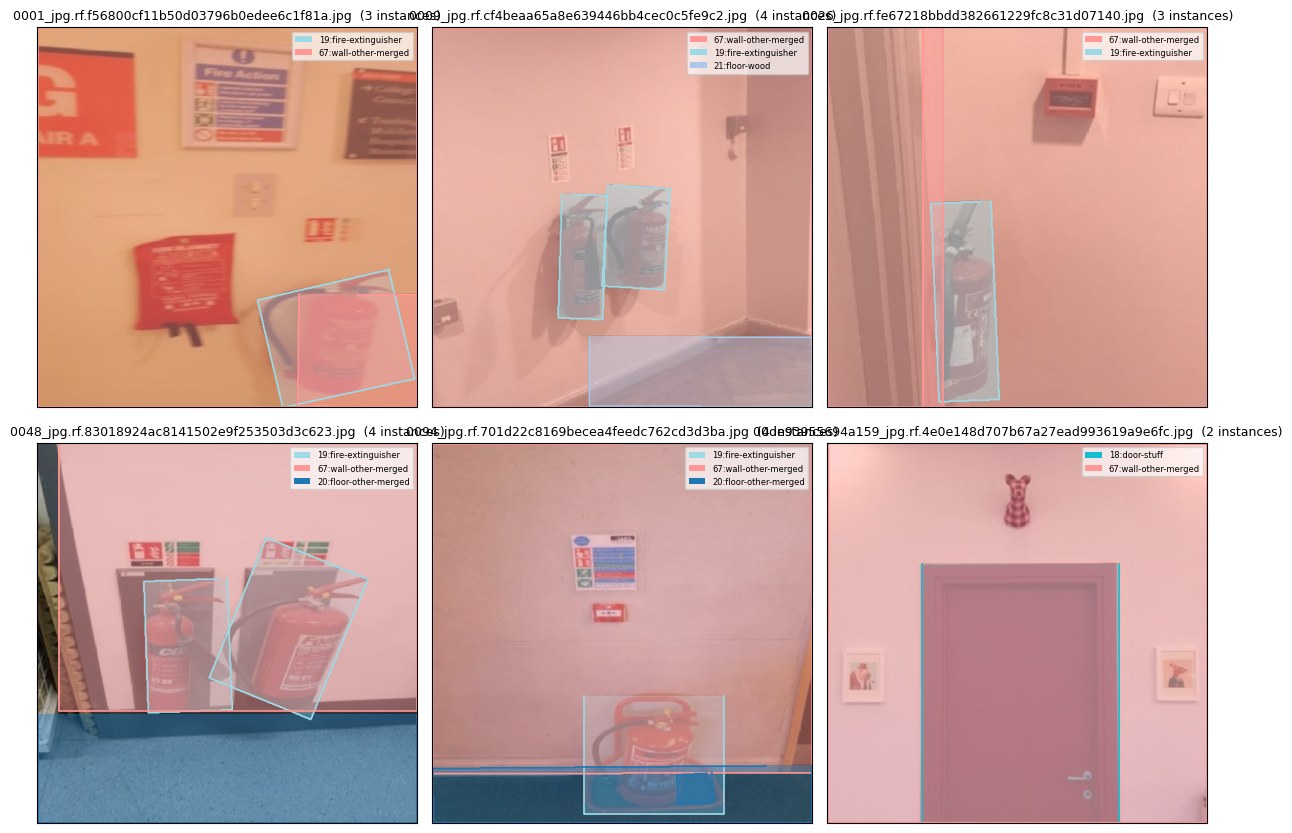

In [8]:
PALETTE = np.array(plt.get_cmap("tab20").colors)


def draw_instances(ax, image, masks, labels, scores=None, alpha=0.45, title=None, legend=True):
    ax.imshow(image)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    seen = []
    for i, (m, lab) in enumerate(zip(masks, labels)):
        m = np.asarray(m) > 0
        if m.sum() == 0:
            continue
        color = PALETTE[int(lab) % len(PALETTE)]
        overlay = np.zeros((*m.shape, 4), np.float32)
        overlay[m] = (*color[:3], alpha)
        ax.imshow(overlay)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            ax.plot(c[:, 0, 0], c[:, 0, 1], color=color, lw=1.2)
        seen.append(int(lab))
    if legend and seen:
        handles = [Patch(facecolor=PALETTE[l % len(PALETTE)], label=f"{l}:{CLASS_NAMES[l]}")
                   for l in dict.fromkeys(seen) if l < len(CLASS_NAMES)]
        ax.legend(handles=handles, loc="upper right", fontsize=6, framealpha=0.7)


def load_rgb(path):
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"))


def masks_from_instances(instances, S=IMG_SIZE):
    masks, labels = [], []
    for inst in instances:
        m = np.zeros((S, S), np.uint8)
        cv2.fillPoly(m, [np.round(inst["poly"]).astype(np.int32)], 1)
        if m.any():
            masks.append(m)
            labels.append(inst["cls"])
    return masks, labels


show = sorted((DS_ROOT / "images" / "train").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 8.6))
for ax, p in zip(axes.ravel(), show):
    masks, labels = masks_from_instances(read_labels(TRAIN_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(ax, load_rgb(p), masks, labels, title=f"{p.name}  ({len(masks)} instances)")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Augmentation (shared by Mask R-CNN and Mask2Former)

One Albumentations pipeline, used on the fly in the `Dataset.__getitem__` (nothing is
written to disk):

| op | why |
|----|-----|
| `RandomResizedCrop(scale 0.6-1.0)` | scale/translation/occlusion robustness, works on masks |
| `HorizontalFlip`, `VerticalFlip(0.2)` | photos are shot from arbitrary angles |
| `Affine(rotate +-12, translate 5%, scale 0.9-1.1)` | geometric jitter |
| `ColorJitter`, `RandomBrightnessContrast`, `HueSaturationValue` | the kitchen shots vary a lot in lighting |
| `MotionBlur`/`GaussNoise` | phone-camera artefacts |

The pipeline transforms **masks directly** (no `bbox_params`): boxes are recomputed from
the augmented masks afterwards, so a box/label can never be dropped without its mask.
Instances that are fully cropped away are removed by the dataset's area check.
Ultralytics uses its own equivalent set (`mosaic`, `degrees`, `scale`, `fliplr`, `hsv_*`,
`copy_paste`), configured in the YOLO section.

In [9]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)
print("albumentations", A.__version__)

def build_train_transform(level="aug 2", S: int = IMG_SIZE):
    # Masks are the source of truth: no bbox_params here. Albumentations filters
    # bboxes (and label_fields) independently of `masks`, which can leave the two
    # lists with different lengths. Boxes are recomputed from the augmented masks
    # in YoloSegDataset.__getitem__, so labels/masks can never get out of sync.

    if level == "no aug":
        return A.Compose([])
    elif level == "aug 1":
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.95, 1.05), translate_percent=(-0.02, 0.02), rotate=(-5, 5),
                     border_mode=cv2.BORDER_CONSTANT, fill=PAD_VALUE, fill_mask=0, p=0.3),
            A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02, p=0.5),
        ])
    else:  # "aug 2" (the original heavy augmentation pipeline)
        return A.Compose([
            A.RandomResizedCrop(size=(S, S), scale=(0.6, 1.0), ratio=(0.75, 1.33), p=1.0),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-12, 12),
                     border_mode=cv2.BORDER_CONSTANT, fill=PAD_VALUE, fill_mask=0, p=0.5),
            A.OneOf([A.MotionBlur(blur_limit=3, p=1.0), A.GaussNoise(p=1.0)], p=0.2),
            A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05, p=0.8),
            A.RandomBrightnessContrast(p=0.3),
            A.HueSaturationValue(p=0.2),
        ])

TRAIN_TF = build_train_transform(AUG_LEVEL)
print(f"Augmentation Level: {AUG_LEVEL}")
print(TRAIN_TF)


albumentations 2.0.8
Augmentation Level: aug 2
Compose([
  RandomResizedCrop(p=1.0, area_for_downscale=None, interpolation=1, mask_interpolation=0, ratio=(0.75, 1.33), scale=(0.6, 1.0), size=(512, 512)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.2),
  Affine(p=0.5, balanced_scale=False, border_mode=0, fill=114.0, fill_mask=0.0, fit_output=False, interpolation=1, keep_ratio=False, mask_interpolation=0, rotate=(-12.0, 12.0), rotate_method='largest_box', scale={'x': (0.9, 1.1), 'y': (0.9, 1.1)}, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, translate_percent={'x': (-0.05, 0.05), 'y': (-0.05, 0.05)}, translate_px=None),
  OneOf([
    MotionBlur(p=1.0, allow_shifted=True, angle_range=(0.0, 360.0), blur_limit=(3, 3), direction_range=(-1.0, 1.0)),
    GaussNoise(p=1.0, mean_range=(0.0, 0.0), noise_scale_factor=1.0, per_channel=True, std_range=(0.2, 0.44)),
  ], p=0.2),
  ColorJitter(p=0.8, brightness=(0.7, 1.3), contrast=(0.7, 1.3), hue=(-0.05, 0.05), saturation=(0.7, 1.3)),
  RandomBrightnessC

## 5. Shared PyTorch plumbing

`YoloSegDataset` serves **both** torchvision-style models and the Hugging Face
Mask2Former model:

* `as_hf=False` -> `(image_tensor, target)` with `boxes / labels / masks` (torchvision
  expects 1-based labels: `num_classes = NUM_CLASSES + 1`).
* `as_hf=True`  -> `{pixel_values, mask_labels, class_labels}` (0-based labels, one binary
  mask per instance, which is exactly `Mask2FormerForUniversalSegmentation`'s loss input).

Normalisation is ImageNet mean/std for all three models (YOLO is fine with 0-1 input;
Ultralytics does its own).

In [10]:
class YoloSegDataset(Dataset):
    """Simple in-notebook PyTorch Dataset for both Torchvision (Mask R-CNN) and HF (Mask2Former)."""

    def __init__(self, images, labels_dir, transform=None, S=IMG_SIZE, as_hf=False, label_offset=1, cache_ram=True):
        self.images = [Path(p) for p in images]
        self.labels_dir = Path(labels_dir)
        self.transform = transform
        self.S = S
        self.as_hf = as_hf
        self.label_offset = label_offset
        self._mean_t = torch.from_numpy(MEAN)[:, None, None]
        self._std_t = torch.from_numpy(STD)[:, None, None]
        self._raw_cache = None
        self._sample_cache = None

        if cache_ram:
            raw = []
            for p in self.images:
                img = load_rgb(p)
                insts = read_labels(self.labels_dir / f"{p.stem}.txt", self.S, self.S)
                masks_list, labels_list = self._rasterize(insts)
                raw.append((img, masks_list, labels_list))
            if self.transform is None:
                # Validation/no-aug: precompute final tensors once (zero CPU work per epoch)
                self._sample_cache = [
                    self._pack(idx, img, masks_list, labels_list)
                    for idx, (img, masks_list, labels_list) in enumerate(raw)
                ]
            else:
                # Training: keep pre-rasterized masks in RAM (skips cv2.fillPoly every epoch)
                self._raw_cache = raw

    def _rasterize(self, insts):
        masks_list, labels_list = [], []
        for inst in insts:
            m = np.zeros((self.S, self.S), np.uint8)
            cv2.fillPoly(m, [np.round(inst["poly"]).astype(np.int32)], 1)
            if m.any():
                masks_list.append(m)
                labels_list.append(inst["cls"] + self.label_offset)
        return masks_list, labels_list

    def _pack(self, idx, img, masks_list, labels_list):
        # Filter out masks that became too small (< 8 px) after augmentation
        valid = []
        for m, lbl in zip(masks_list, labels_list):
            area = int(m.sum())
            if area >= 8:
                valid.append((m, lbl, float(area)))

        if valid:
            masks = np.stack([v[0] for v in valid])
            labels = np.array([v[1] for v in valid], dtype=np.int64)
            areas = np.array([v[2] for v in valid], dtype=np.float32)
        else:
            masks = np.zeros((0, self.S, self.S), dtype=np.uint8)
            labels = np.zeros(0, dtype=np.int64)
            areas = np.zeros(0, dtype=np.float32)

        x = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float().div_(255.0)
        x = (x - self._mean_t) / self._std_t

        if self.as_hf:
            # Keep mask_labels as uint8 [K, H, W] on CPU (4x less RAM/IPC); cast to float32 on GPU.
            return {
                "pixel_values": x,
                "mask_labels": torch.from_numpy(masks),
                "class_labels": torch.from_numpy(labels - self.label_offset),
            }

        boxes = [polygon_bbox_from_mask(m) for m in masks]
        return x, {
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.from_numpy(labels),
            "masks": torch.from_numpy(masks),
            "image_id": torch.tensor([idx]),
            "area": torch.tensor(areas, dtype=torch.float32),
            "iscrowd": torch.zeros(len(masks), dtype=torch.int64),
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        if self._sample_cache is not None:
            return self._sample_cache[idx]

        if self._raw_cache is not None:
            img, masks_list, labels_list = self._raw_cache[idx]
            img = img.copy()
        else:
            p = self.images[idx]
            img = load_rgb(p)
            insts = read_labels(self.labels_dir / f"{p.stem}.txt", self.S, self.S)
            masks_list, labels_list = self._rasterize(insts)

        if self.transform is not None and masks_list:
            out = self.transform(image=img, masks=masks_list)
            img, masks_list = out["image"], out["masks"]
        elif self.transform is not None:
            img = self.transform(image=img)["image"]

        return self._pack(idx, img, masks_list, labels_list)


def polygon_bbox_from_mask(mask):
    rows = np.flatnonzero(mask.any(axis=1))
    if rows.size == 0:
        return [0.0, 0.0, 1.0, 1.0]
    cols = np.flatnonzero(mask.any(axis=0))
    return [float(cols[0]), float(rows[0]), float(cols[-1] + 1), float(rows[-1] + 1)]


def dataloader_worker_init(_worker_id):
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)


def detection_collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


def hf_collate(batch):
    return {
        "pixel_values": torch.stack([b["pixel_values"] for b in batch]),
        "mask_labels": [b["mask_labels"] for b in batch],
        "class_labels": [b["class_labels"] for b in batch],
    }


print("Simplified in-notebook dataset loader ready")

Simplified in-notebook dataset loader ready


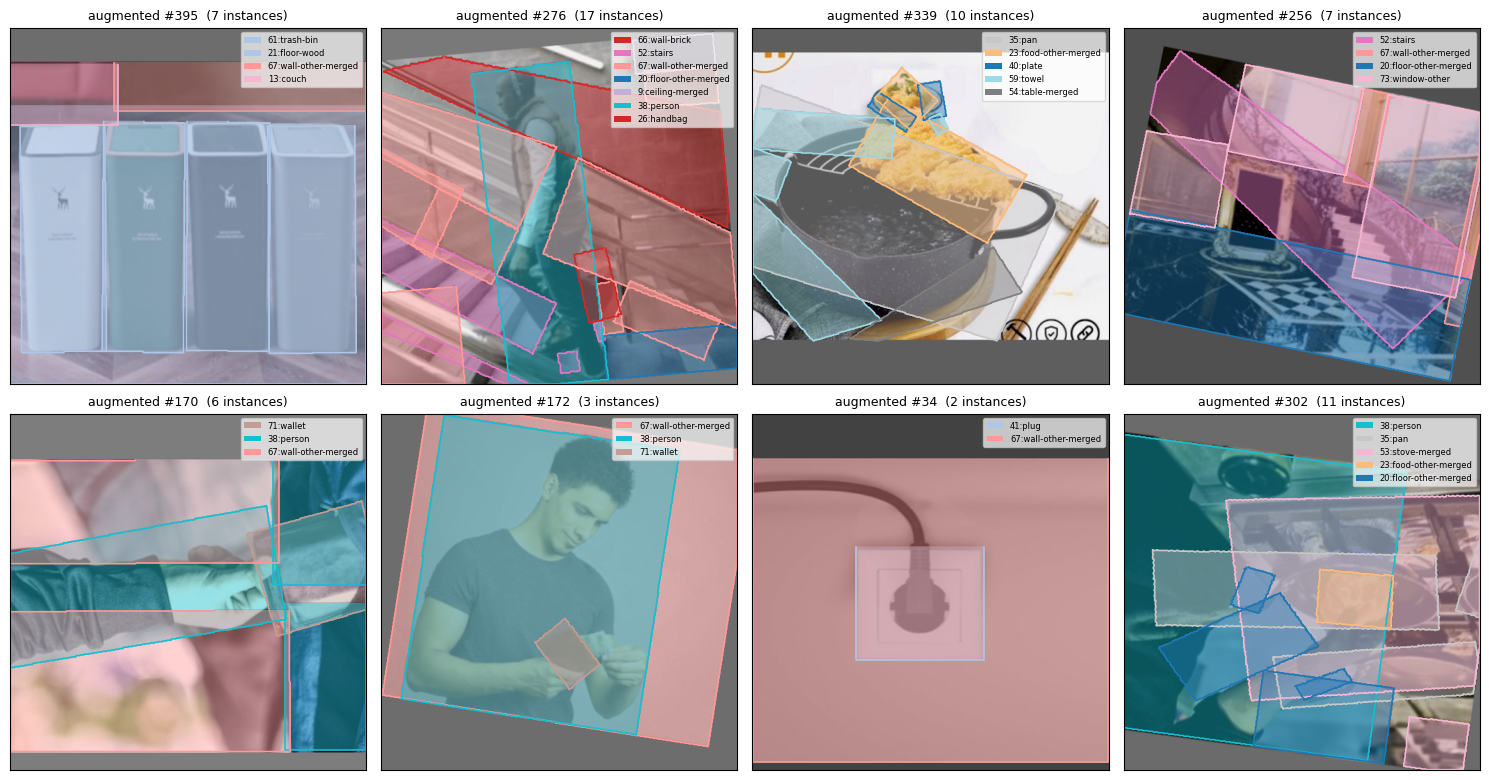

Same pipeline now feeds Mask R-CNN and Mask2Former; YOLO uses its internal augs.


In [11]:
ds_preview = YoloSegDataset(TRAIN_IMAGES, TRAIN_LABELS, transform=TRAIN_TF, as_hf=False, cache_ram=False)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
idxs = np.random.default_rng(SEED).choice(len(ds_preview), size=8, replace=False)
for ax, i in zip(axes.ravel(), idxs):
    x, t = ds_preview[int(i)]
    img = (x.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
    draw_instances(ax, img, t["masks"].numpy(), (t["labels"].numpy() - 1),
                   title=f"augmented #{int(i)}  ({len(t['labels'])} instances)")
plt.tight_layout()
plt.show()
del ds_preview
print("Same pipeline now feeds Mask R-CNN and Mask2Former; YOLO uses its internal augs.")

## 6. Model 1 - YOLO11n-seg  (one-stage, anchor-free)

In [12]:
YOLO_WEIGHTS = "yolo11n-seg.pt"
YOLO_EPOCHS = EPOCHS["yolo"]

yolo = YOLO(YOLO_WEIGHTS)
yolo.info()

yolo.train(
    data=str(DATA_YAML),
    epochs=YOLO_EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE["yolo"],
    device=0 if DEVICE.type == "cuda" else "cpu",
    project=str(OUT_DIR / "yolo"),
    name=f"yolo11n_seg_{IMG_SIZE}",
    exist_ok=True,
    seed=SEED,
    deterministic=False,
    workers=NUM_WORKERS,
    cache="ram",
    patience=max(10, YOLO_EPOCHS // 3),
    optimizer="auto",
    lr0=0.01,
    lrf=0.01,
    cos_lr=True,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    amp=USE_AMP,
    # --- augmentation (in the YOLO dataloader, at 512 px) ---
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10.0, translate=0.1, scale=0.3, shear=2.0, perspective=0.0,
    fliplr=0.5, flipud=0.2, mosaic=0.5, mixup=0.0, copy_paste=0.1, close_mosaic=5,
    plots=True,
    verbose=False,
)

YOLO_RUN = Path(yolo.trainer.save_dir)
BEST_YOLO = YOLO_RUN / "weights" / "best.pt"
print("run dir :", YOLO_RUN)
print("best ckpt:", BEST_YOLO, BEST_YOLO.exists())

YOLO11n-seg summary: 203 layers, 2,876,848 parameters, 0 gradients, 10.0 GFLOPs
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset_512/data.yaml, degrees=10.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.2, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=0

In [13]:
yolo_best = YOLO(str(BEST_YOLO))
ym = yolo_best.val(data=str(DATA_YAML), imgsz=IMG_SIZE, batch=BATCH_SIZE["yolo"],
                   device=0 if DEVICE.type == "cuda" else "cpu", plots=False, verbose=False)
YOLO_METRICS = {
    "seg mAP50-95": float(ym.seg.map),
    "seg mAP50": float(ym.seg.map50),
    "box mAP50": float(ym.box.map50),
}
print(json.dumps(YOLO_METRICS, indent=2))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1507.7±543.5 MB/s, size: 59.5 KB)
val: Scanning /content/dataset_512/labels/val.cache... 166 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 166/166 58.0Mit/s 0.0s
val: /content/dataset_512/images/val/182169057_jpg.rf.9a73794dc31984a272e84d9823d9a812.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.9s1.1s
                   all        166       2021      0.578      0.257      0.291      0.173      0.581      0.206      0.216      0.103
Speed: 0.5ms preprocess, 2.4ms inference, 0.0ms loss, 1.5ms postprocess per image
{
  "seg mAP50-95": 0.10326607512429957,
  "seg mAP50": 0.21568086898096028,
  "box mAP50": 0.290502319

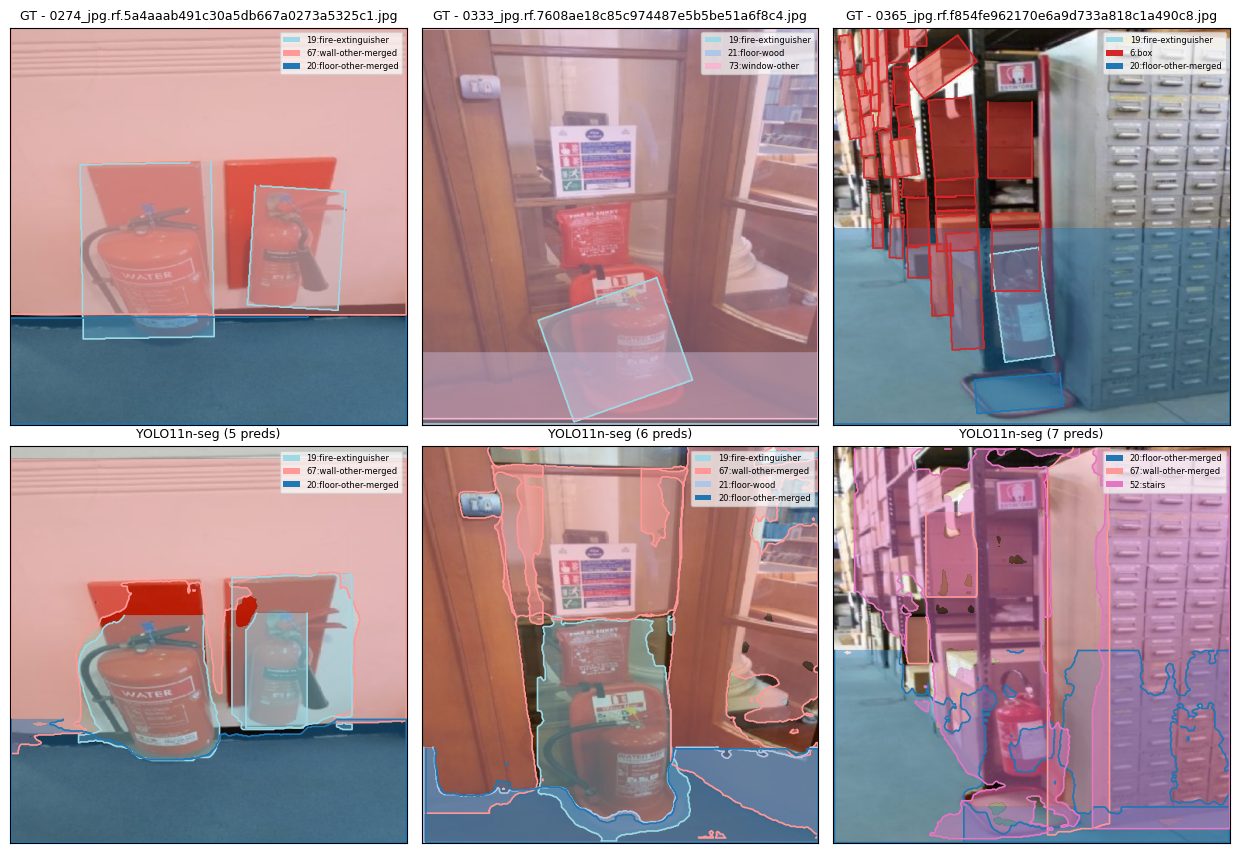

In [14]:
def yolo_predict(model, image_paths, conf=0.25, iou=0.6, max_det=50, batch_size=None):
    '''Uniform prediction format: list of {masks, labels(0-based), scores}.'''
    bs = batch_size or BATCH_SIZE["yolo"]
    out = []
    for i in range(0, len(image_paths), bs):
        chunk = [str(p) for p in image_paths[i:i + bs]]
        results = model.predict(chunk, imgsz=IMG_SIZE, conf=conf, iou=iou, max_det=max_det,
                                retina_masks=True, verbose=False)
        for r in results:
            if r.masks is None or len(r.masks) == 0:
                out.append({"masks": np.zeros((0, IMG_SIZE, IMG_SIZE), bool),
                            "labels": np.zeros(0, np.int64), "scores": np.zeros(0, np.float32)})
                continue
            masks = r.masks.data.cpu().numpy() > 0.5
            if masks.shape[-1] != IMG_SIZE:
                masks = np.stack([cv2.resize(m.astype(np.uint8), (IMG_SIZE, IMG_SIZE),
                                             interpolation=cv2.INTER_NEAREST).astype(bool) for m in masks])
            out.append({"masks": masks,
                        "labels": r.boxes.cls.cpu().numpy().astype(np.int64),
                        "scores": r.boxes.conf.cpu().numpy()})
    return out


demo = VAL_IMAGES[:3]
yolo_preds = yolo_predict(YOLO(YOLO_WEIGHTS) if not BEST_YOLO.exists() else yolo_best, demo)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.6))
for j, (p, pred) in enumerate(zip(demo, yolo_preds)):
    gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(axes[0, j], load_rgb(p), gt_m, gt_l, title=f"GT - {p.name}")
    draw_instances(axes[1, j], load_rgb(p), pred["masks"], pred["labels"],
                   title=f"YOLO11n-seg ({len(pred['masks'])} preds)")
plt.tight_layout()
plt.show()

# Free YOLO GPU memory before Mask R-CNN (section 9 reloads BEST_YOLO from disk)
for _v in ("yolo", "yolo_best", "ym"):
    if _v in globals():
        del globals()[_v]
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 7. Model 2 - Mask R-CNN (ResNet-50-FPN, two-stage)

In [15]:
def build_maskrcnn(num_classes, pretrained=True):
    weights = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT if pretrained else None
    model = maskrcnn_resnet50_fpn_v2(weights=weights, min_size=IMG_SIZE, max_size=IMG_SIZE)
    model.roi_heads.box_predictor = FastRCNNPredictor(
        model.roi_heads.box_predictor.cls_score.in_features, num_classes)
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        model.roi_heads.mask_predictor.conv5_mask.in_channels, 256, num_classes)
    return model


maskrcnn = build_maskrcnn(NUM_CLASSES + 1).to(DEVICE)
n_params = sum(p.numel() for p in maskrcnn.parameters() if p.requires_grad)
print(f"Mask R-CNN params: {n_params / 1e6:.1f} M   (classes={NUM_CLASSES + 1})")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 194MB/s]  


Mask R-CNN params: 46.0 M   (classes=75)


In [16]:
train_ds = YoloSegDataset(TRAIN_IMAGES, TRAIN_LABELS, transform=TRAIN_TF, as_hf=False)
val_ds = YoloSegDataset(VAL_IMAGES, VAL_LABELS, transform=None, as_hf=False)

_dl_extra = {"persistent_workers": True, "prefetch_factor": 2, "worker_init_fn": dataloader_worker_init} if NUM_WORKERS > 0 else {}
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE["maskrcnn"], shuffle=True,
                          num_workers=NUM_WORKERS, collate_fn=detection_collate,
                          pin_memory=USE_AMP, drop_last=len(train_ds) > BATCH_SIZE["maskrcnn"],
                          **_dl_extra)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE["maskrcnn"], shuffle=False,
                        num_workers=NUM_WORKERS, collate_fn=detection_collate,
                        pin_memory=USE_AMP, **_dl_extra)

print(f"train batches: {len(train_loader)}  val batches: {len(val_loader)}")


def amp_ctx():
    if not USE_AMP:
        return contextlib.nullcontext()
    dtype = torch.bfloat16 if USE_BF16 else torch.float16
    return torch.autocast("cuda", dtype=dtype)


def move_targets(targets):
    return [{k: (v.to(DEVICE, non_blocking=USE_AMP) if torch.is_tensor(v) else v) for k, v in t.items()} for t in targets]

train batches: 24  val batches: 11


In [17]:
from tqdm.auto import tqdm

MRCNN_DIR = OUT_DIR / "maskrcnn"
MRCNN_DIR.mkdir(parents=True, exist_ok=True)

params = [p for p in maskrcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=LR["maskrcnn"], momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS["maskrcnn"])
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and not USE_BF16)


@torch.no_grad()
def maskrcnn_val_loss(model, loader):
    model.train()                      # losses are only produced in train mode
    totals, n = {}, 0
    for images, targets in loader:
        images, targets = [i.to(DEVICE, non_blocking=USE_AMP) for i in images], move_targets(targets)
        with amp_ctx():
            loss_dict = model(images, targets)
        for k, v in loss_dict.items():
            vd = v.detach().float()
            totals[k] = vd if k not in totals else totals[k] + vd
        n += 1
    return {k: float(v.item()) / max(n, 1) for k, v in totals.items()}


mrcnn_history, best_val = [], float("inf")
for epoch in range(EPOCHS["maskrcnn"]):
    maskrcnn.train()
    running, seen = {}, 0
    pbar = tqdm(train_loader, desc=f"Mask R-CNN {epoch + 1}/{EPOCHS['maskrcnn']}", leave=False)
    for images, targets in pbar:
        images, targets = [i.to(DEVICE, non_blocking=USE_AMP) for i in images], move_targets(targets)
        with amp_ctx():
            loss_dict = maskrcnn(images, targets)
            loss = sum(v.float() for v in loss_dict.values())
        opt.zero_grad(set_to_none=True)
        if scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 5.0)
            scaler.step(opt)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 5.0)
            opt.step()
        for k, v in loss_dict.items():
            vd = v.detach().float()
            running[k] = vd if k not in running else running[k] + vd
        seen += 1
        if seen % 5 == 0 or seen == len(train_loader):
            pbar.set_postfix(loss=f"{loss.detach().item():.3f}")

    train_loss = {k: float(v.item()) / max(seen, 1) for k, v in running.items()}
    val_loss = maskrcnn_val_loss(maskrcnn, val_loader)
    sched.step()
    row = {"epoch": epoch + 1, "lr": opt.param_groups[0]["lr"],
           **{f"train_{k}": v for k, v in train_loss.items()},
           **{f"val_{k}": v for k, v in val_loss.items()}}
    mrcnn_history.append(row)
    total_val = sum(val_loss.values())
    if total_val < best_val:
        best_val = total_val
        torch.save({"model": maskrcnn.state_dict(), "classes": CLASS_NAMES, "img_size": IMG_SIZE},
                   MRCNN_DIR / "best.pt")
    print(f"epoch {epoch + 1:02d} | train {sum(train_loss.values()):.3f} | "
          f"val {total_val:.3f} | lr {row['lr']:.5f}")

torch.save({"model": maskrcnn.state_dict(), "classes": CLASS_NAMES, "img_size": IMG_SIZE},
           MRCNN_DIR / "last.pt")
print("saved:", MRCNN_DIR / "best.pt")

Mask R-CNN 1/50:   0%|          | 0/24 [00:00<?, ?it/s]

epoch 01 | train 3.177 | val 2.538 | lr 0.01499


Mask R-CNN 2/50:   0%|          | 0/24 [00:00<?, ?it/s]

epoch 02 | train 2.239 | val 2.206 | lr 0.01494


Mask R-CNN 3/50:   0%|          | 0/24 [00:00<?, ?it/s]

epoch 03 | train 2.034 | val 2.047 | lr 0.01487


... (90 outputs left out)

Mask R-CNN 49/50:   0%|          | 0/24 [00:00<?, ?it/s]

epoch 49 | train 0.944 | val 1.738 | lr 0.00001


Mask R-CNN 50/50:   0%|          | 0/24 [00:00<?, ?it/s]

epoch 50 | train 0.929 | val 1.739 | lr 0.00000
saved: /content/outputs/maskrcnn/best.pt


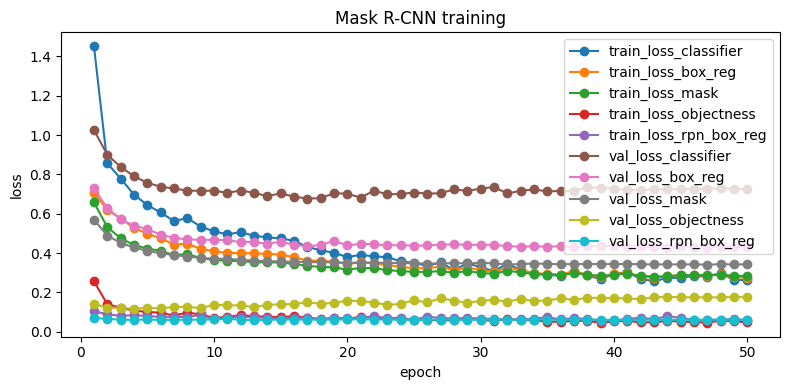

,epoch,lr,train_loss_classifier,train_loss_box_reg,train_loss_mask,train_loss_objectness,train_loss_rpn_box_reg,val_loss_classifier,val_loss_box_reg,val_loss_mask,val_loss_objectness,val_loss_rpn_box_reg
45,46,0.0002,0.2841,0.2883,0.2875,0.0491,0.0603,0.7247,0.4298,0.3430,0.1751,0.0615
46,47,0.0001,0.2796,0.2842,0.2891,0.0470,0.0599,0.7281,0.4274,0.3409,0.1756,0.0619
47,48,0.0001,0.2983,0.2958,0.2906,0.0575,0.0626,0.7285,0.4316,0.3438,0.1750,0.0619
48,49,0.0000,0.2638,0.2777,0.2847,0.0529,0.0654,0.7267,0.4307,0.3426,0.1769,0.0613
49,50,0.0000,0.2627,0.2755,0.2837,0.0489,0.0582,0.7262,0.4327,0.3427,0.1756,0.0622


In [18]:
hist = pd.DataFrame(mrcnn_history)
ax = hist.set_index("epoch")[[c for c in hist.columns if c.startswith(("train_loss", "val_loss"))]] \
         .plot(figsize=(8, 4), marker="o")
ax.set_title("Mask R-CNN training")
ax.set_ylabel("loss")
plt.tight_layout()
plt.show()
hist.tail().round(4)

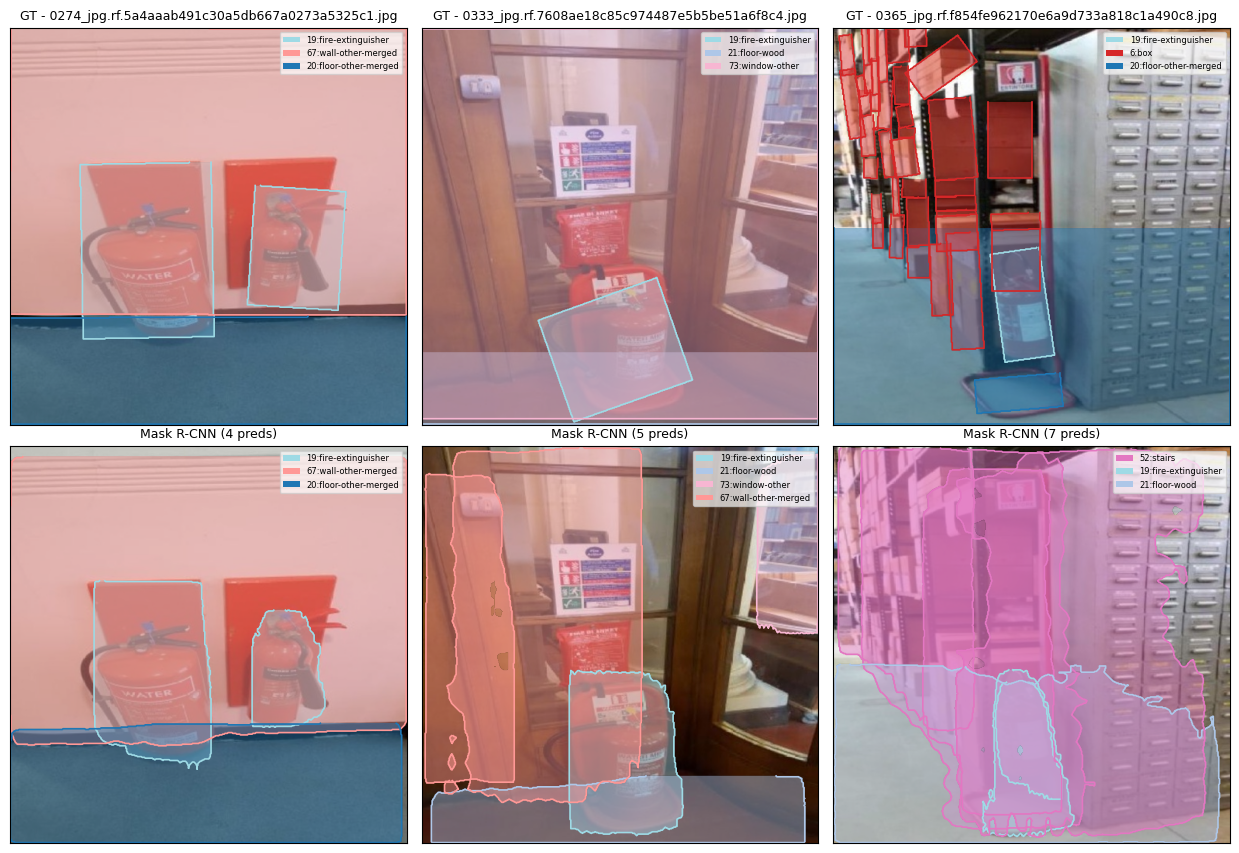

In [19]:
@torch.no_grad()
def maskrcnn_predict(model, image_paths, score_thr=0.5, max_det=50, batch_size=None):
    '''Uniform prediction format: list of {masks, labels(0-based), scores}.'''
    model.to(DEVICE).eval()
    bs = batch_size or BATCH_SIZE["maskrcnn"]
    t_mean, t_std = torch.from_numpy(MEAN)[:, None, None], torch.from_numpy(STD)[:, None, None]
    out = []
    for i in range(0, len(image_paths), bs):
        xs = []
        for p in image_paths[i:i + bs]:
            x = torch.from_numpy(load_rgb(p)).permute(2, 0, 1).float().div(255.0)
            xs.append(((x - t_mean) / t_std).to(DEVICE, non_blocking=USE_AMP))
        with amp_ctx():
            preds = model(xs)
        for pred in preds:
            keep = torch.nonzero(pred["scores"] > score_thr).squeeze(1)[:max_det]
            out.append({"masks": pred["masks"][keep, 0].cpu().numpy() > 0.5,
                        "labels": pred["labels"][keep].cpu().numpy().astype(np.int64) - 1,
                        "scores": pred["scores"][keep].cpu().numpy()})
    return out


maskrcnn_eval = build_maskrcnn(NUM_CLASSES + 1, pretrained=False).to(DEVICE)
maskrcnn_eval.load_state_dict(torch.load(MRCNN_DIR / "best.pt", map_location=DEVICE)["model"])
maskrcnn_eval.eval()

mrcnn_preds = maskrcnn_predict(maskrcnn_eval, demo)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.6))
for j, (p, pred) in enumerate(zip(demo, mrcnn_preds)):
    gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(axes[0, j], load_rgb(p), gt_m, gt_l, title=f"GT - {p.name}")
    draw_instances(axes[1, j], load_rgb(p), pred["masks"], pred["labels"],
                   title=f"Mask R-CNN ({len(pred['masks'])} preds)")
plt.tight_layout()
plt.show()

# Free all Mask R-CNN training VRAM & RAM caches before loading Mask2Former
maskrcnn_eval.cpu()
for _v in ("maskrcnn", "opt", "sched", "scaler", "params", "loss", "loss_dict",
           "images", "targets", "train_loader", "val_loader", "train_ds", "val_ds"):
    if _v in globals():
        del globals()[_v]
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 8. Model 3 - Mask2Former (Swin-Tiny, transformer)

In [20]:
import gc
gc.collect()
torch.cuda.empty_cache()

M2F_CKPT = "facebook/mask2former-swin-tiny-coco-instance"
m2f_config = Mask2FormerConfig.from_pretrained(M2F_CKPT)
m2f_config.num_labels = NUM_CLASSES
m2f_config.use_auxiliary_loss = True

mask2former = Mask2FormerForUniversalSegmentation.from_pretrained(
    M2F_CKPT, config=m2f_config, ignore_mismatched_sizes=True
).to(DEVICE)

# used only for post-processing (instances -> binary masks)
m2f_processor = Mask2FormerImageProcessor(
    size={"height": IMG_SIZE, "width": IMG_SIZE}, ignore_index=255, reduce_labels=False
)

print(f"Mask2Former params: {sum(p.numel() for p in mask2former.parameters()) / 1e6:.1f} M")
print("num_labels:", mask2former.config.num_labels, "| queries:", mask2former.config.num_queries)

config.json:   0%|          | 0.00/79.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  190MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    |                                    

Mask2Former params: 47.4 M
num_labels: 74 | queries: 100


In [21]:
hf_train_ds = YoloSegDataset(TRAIN_IMAGES, TRAIN_LABELS, transform=TRAIN_TF, as_hf=True)
hf_val_ds = YoloSegDataset(VAL_IMAGES, VAL_LABELS, transform=None, as_hf=True)

hf_train_loader = DataLoader(hf_train_ds, batch_size=BATCH_SIZE["mask2former"], shuffle=True,
                             num_workers=NUM_WORKERS, collate_fn=hf_collate, pin_memory=USE_AMP,
                             **_dl_extra)
hf_val_loader = DataLoader(hf_val_ds, batch_size=BATCH_SIZE["mask2former"], shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=hf_collate, pin_memory=USE_AMP,
                           **_dl_extra)

batch = next(iter(hf_train_loader))
print({k: (tuple(v.shape) if torch.is_tensor(v) else f"list[{len(v)}] of {tuple(v[0].shape)}")
       for k, v in batch.items()})

{'pixel_values': (4, 3, 512, 512), 'mask_labels': 'list[4] of (7, 512, 512)', 'class_labels': 'list[4] of (7,)'}


In [22]:
M2F_DIR = OUT_DIR / "mask2former"
M2F_DIR.mkdir(parents=True, exist_ok=True)

params = [p for p in mask2former.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR["mask2former"], weight_decay=0.05, fused=(DEVICE.type == "cuda"))
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS["mask2former"])
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and not USE_BF16)


@torch.no_grad()
def mask2former_val_loss(model, loader):
    model.eval()
    total, n = torch.zeros((), device=DEVICE), 0
    for batch in loader:
        pv = batch["pixel_values"].to(DEVICE, non_blocking=USE_AMP)
        ml = [m.to(DEVICE, non_blocking=USE_AMP, dtype=torch.float32) for m in batch["mask_labels"]]
        cl = [c.to(DEVICE, non_blocking=USE_AMP) for c in batch["class_labels"]]
        if sum(len(c) for c in cl) == 0:
            continue
        with amp_ctx():
            loss = model(pixel_values=pv, mask_labels=ml, class_labels=cl).loss
        total = total + loss.detach().float()
        n += 1
    return float(total.item()) / max(n, 1)


m2f_history, best_val = [], float("inf")
for epoch in range(EPOCHS["mask2former"]):
    mask2former.train()
    running, seen = torch.zeros((), device=DEVICE), 0
    pbar = tqdm(hf_train_loader, desc=f"Mask2Former {epoch + 1}/{EPOCHS['mask2former']}", leave=False)
    for batch in pbar:
        pv = batch["pixel_values"].to(DEVICE, non_blocking=USE_AMP)
        ml = [m.to(DEVICE, non_blocking=USE_AMP, dtype=torch.float32) for m in batch["mask_labels"]]
        cl = [c.to(DEVICE, non_blocking=USE_AMP) for c in batch["class_labels"]]
        if sum(len(c) for c in cl) == 0:      # nothing to match against
            continue

        with amp_ctx():
            loss = mask2former(pixel_values=pv, mask_labels=ml, class_labels=cl).loss
        opt.zero_grad(set_to_none=True)
        if scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 0.01)
            scaler.step(opt)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 0.01)
            opt.step()

        running = running + loss.detach().float()
        seen += 1
        if seen % 5 == 0 or seen == len(hf_train_loader):
            pbar.set_postfix(loss=f"{loss.detach().item():.3f}")

    train_epoch_loss = float(running.item()) / max(seen, 1)
    val = mask2former_val_loss(mask2former, hf_val_loader)
    sched.step()
    m2f_history.append({"epoch": epoch + 1, "train_loss": train_epoch_loss,
                        "val_loss": val, "lr": opt.param_groups[0]["lr"]})
    if val < best_val:
        best_val = val
        mask2former.save_pretrained(M2F_DIR)
        m2f_processor.save_pretrained(M2F_DIR)
    print(f"epoch {epoch + 1:02d} | train {train_epoch_loss:.3f} | val {val:.3f} | "
          f"lr {opt.param_groups[0]['lr']:.2e}")

# keep the last state too
mask2former.save_pretrained(M2F_DIR / "last")
print("saved:", M2F_DIR)

Mask2Former 1/25:   0%|          | 0/100 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 01 | train 86.641 | val 74.391 | lr 1.99e-04


Mask2Former 2/25:   0%|          | 0/100 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 02 | train 75.825 | val 68.998 | lr 1.97e-04


... (59 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 25 | train 37.835 | val 49.316 | lr 0.00e+00


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: /content/outputs/mask2former


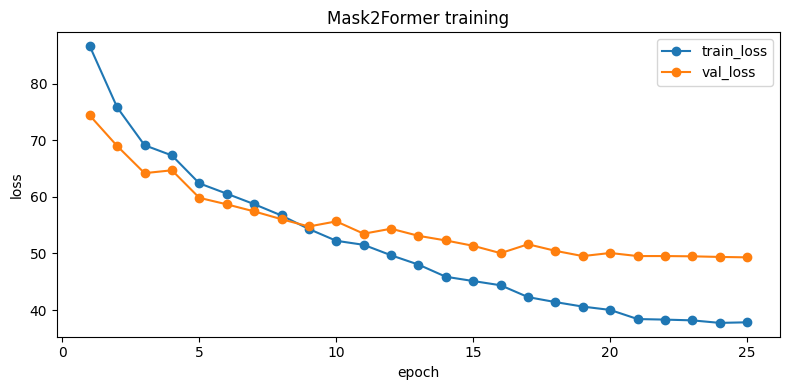

In [23]:
pd.DataFrame(m2f_history).set_index("epoch")[["train_loss", "val_loss"]].plot(
    figsize=(8, 4), marker="o", title="Mask2Former training")
plt.ylabel("loss")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

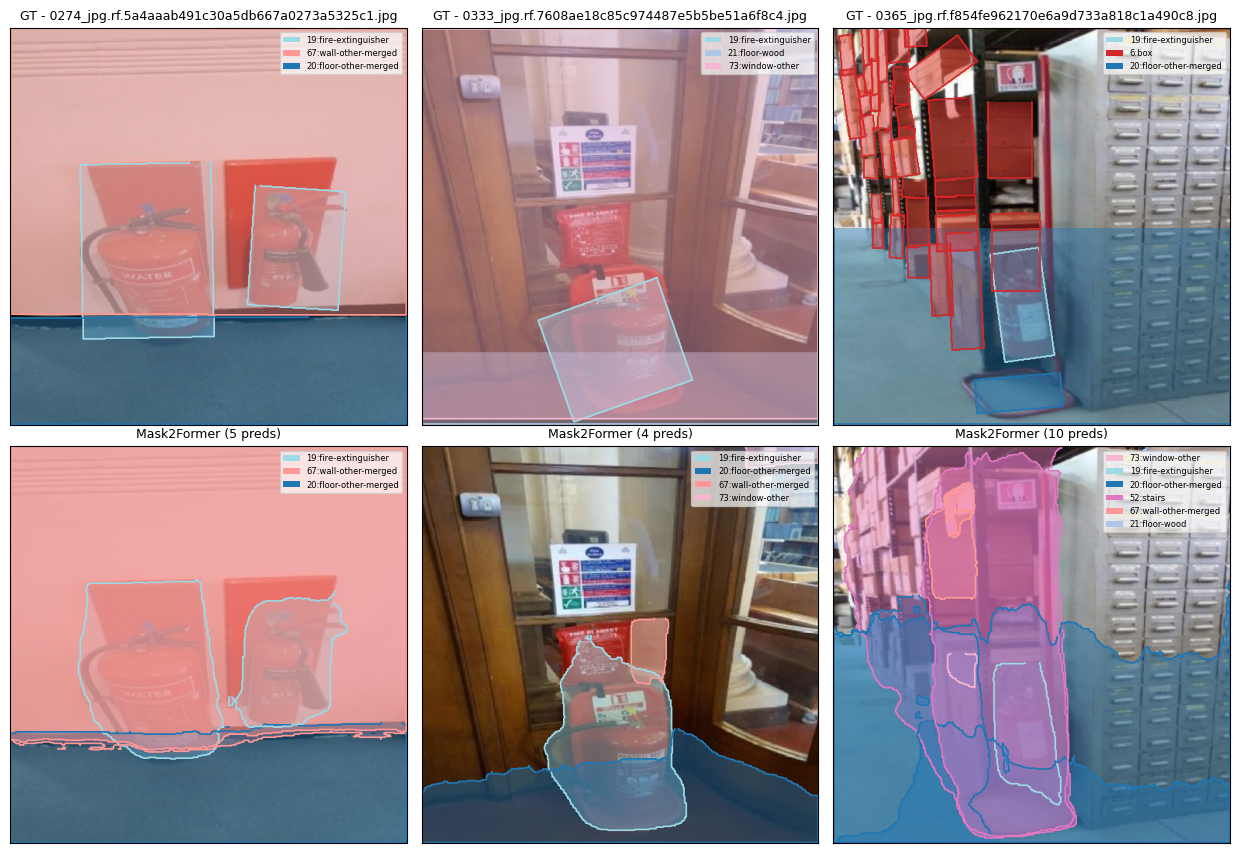

In [24]:
@torch.no_grad()
def mask2former_predict(model, processor, image_paths, score_thr=0.5, max_det=50):
    """Uniform prediction format: list of {masks, labels(0-based), scores}.
    Uses return_binary_maps=True so high-index queries do not overwrite earlier queries
    on a single 2D canvas when score_thr is low during mAP evaluation.
    """
    model.to(DEVICE).eval()
    t_mean, t_std = torch.from_numpy(MEAN)[:, None, None], torch.from_numpy(STD)[:, None, None]
    xs = []
    for p in image_paths:
        x = torch.from_numpy(np.ascontiguousarray(load_rgb(p))).permute(2, 0, 1).float().div(255.0)
        xs.append((x - t_mean) / t_std)
    pv = torch.stack(xs).to(DEVICE, non_blocking=USE_AMP)
    with amp_ctx():
        outputs = model(pixel_values=pv)
    proc = processor.post_process_instance_segmentation(
        outputs, threshold=score_thr, mask_threshold=0.5,
        overlap_mask_area_threshold=0.8,
        target_sizes=[(IMG_SIZE, IMG_SIZE)] * len(xs),
        return_binary_maps=True,
    )
    out = []
    for d in proc:
        seg = d["segmentation"]
        infos = d["segments_info"][:max_det]
        if seg is None or len(infos) == 0:
            out.append({"masks": np.zeros((0, IMG_SIZE, IMG_SIZE), bool),
                        "labels": np.zeros(0, np.int64), "scores": np.zeros(0, np.float32)})
            continue
        masks = (seg[:len(infos)] > 0.5).cpu().numpy()
        labels = np.array([int(info.get("category_id", info.get("label_id"))) for info in infos], np.int64)
        scores = np.array([float(info["score"]) for info in infos], np.float32)
        out.append({"masks": masks, "labels": labels, "scores": scores})
    return out


# load the best checkpoint written above
if (M2F_DIR / "config.json").exists():
    mask2former_eval = Mask2FormerForUniversalSegmentation.from_pretrained(M2F_DIR).to(DEVICE).eval()
else:
    mask2former_eval = mask2former.eval()

m2f_preds = mask2former_predict(mask2former_eval, m2f_processor, demo)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.6))
for j, (p, pred) in enumerate(zip(demo, m2f_preds)):
    gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(axes[0, j], load_rgb(p), gt_m, gt_l, title=f"GT - {p.name}")
    draw_instances(axes[1, j], load_rgb(p), pred["masks"], pred["labels"],
                   title=f"Mask2Former ({len(pred['masks'])} preds)")
plt.tight_layout()
plt.show()

# Free Mask2Former training state before full evaluation
mask2former_eval.cpu()
for _v in ("mask2former", "opt", "sched", "scaler", "params", "loss", "pv", "ml", "cl",
           "batch", "hf_train_loader", "hf_val_loader", "hf_train_ds", "hf_val_ds"):
    if _v in globals():
        del globals()[_v]
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

## 9. Unified evaluation: mask mAP with pycocotools

In [25]:
coco_gt = COCO(str(EVAL_COCO))
NAME2ID = {v["file_name"]: k for k, v in coco_gt.imgs.items()}


def encode_rle(mask):
    return mask_utils.encode(np.asfortranarray((np.asarray(mask) > 0).astype(np.uint8)))


def to_coco_results(preds, image_paths):
    results = []
    for p, d in zip(image_paths, preds):
        for m, l, s in zip(d["masks"], d["labels"], d["scores"]):
            if m.sum() == 0:
                continue
            results.append({"image_id": NAME2ID[p.name], "category_id": int(l) + 1,
                            "segmentation": encode_rle(m), "score": float(s)})
    return results


def eval_segm(results, name):
    if not results:
        return {"model": name}
    dt = coco_gt.loadRes(results)
    e = COCOeval(coco_gt, dt, "segm")
    e.params.imgIds = sorted(coco_gt.getImgIds())
    e.evaluate()
    e.accumulate()
    with contextlib.redirect_stdout(io.StringIO()):
        e.summarize()
    s = e.stats
    return {"model": name, "mAP@50-95": s[0], "mAP@50": s[1], "mAP@75": s[2],
            "mAP_small": s[3], "mAP_medium": s[4], "mAP_large": s[5], "AR@100": s[8]}


# --- predictions ------------------------------------------------------------
yolo_final = YOLO(str(BEST_YOLO)) if BEST_YOLO.exists() else YOLO(YOLO_WEIGHTS)

t0 = time.time()
res_yolo = to_coco_results(yolo_predict(yolo_final, EVAL_IMAGES, conf=0.001, iou=0.6, max_det=100), EVAL_IMAGES)
print(f"yolo  : {len(res_yolo)} detections, {time.time() - t0:.1f}s")

t0 = time.time()
res_mrcnn = to_coco_results(maskrcnn_predict(maskrcnn_eval, EVAL_IMAGES, score_thr=0.05, max_det=100), EVAL_IMAGES)
maskrcnn_eval.cpu()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print(f"mrcnn : {len(res_mrcnn)} detections, {time.time() - t0:.1f}s")

t0 = time.time()
m2f_all = []
m2f_bs = BATCH_SIZE["mask2former"]
for i in range(0, len(EVAL_IMAGES), m2f_bs):
    m2f_all += mask2former_predict(mask2former_eval, m2f_processor, EVAL_IMAGES[i:i + m2f_bs],
                                   score_thr=0.0, max_det=100)
mask2former_eval.cpu()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
res_m2f = to_coco_results(m2f_all, EVAL_IMAGES)
print(f"m2f   : {len(res_m2f)} detections, {time.time() - t0:.1f}s")

(OUT_DIR / "preds").mkdir(exist_ok=True)
for nm, r in [("yolo", res_yolo), ("maskrcnn", res_mrcnn), ("mask2former", res_m2f)]:
    (OUT_DIR / "preds" / f"{nm}.json").write_text(json.dumps(r, default=lambda o: o.decode() if isinstance(o, bytes) else None))

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
yolo  : 13924 detections, 18.7s
mrcnn : 9696 detections, 22.2s
m2f   : 16344 detections, 32.1s


In [26]:
rows = [
    eval_segm(res_yolo, "YOLO11n-seg"),
    eval_segm(res_mrcnn, "Mask R-CNN (R50-FPN)"),
    eval_segm(res_m2f, "Mask2Former (Swin-T)"),
]

METRICS = pd.DataFrame(rows).set_index("model")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
display_metrics = METRICS.copy()
display_metrics

METRICS.to_csv(OUT_DIR / "metrics_segm.csv")

Loading and preparing results...
DONE (t=0.19s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.85s).
Accumulating evaluation results...
DONE (t=0.47s).
Loading and preparing results...
DONE (t=0.13s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.10s).
Accumulating evaluation results...
DONE (t=0.42s).
Loading and preparing results...
DONE (t=0.26s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.49s).
Accumulating evaluation results...
DONE (t=0.47s).


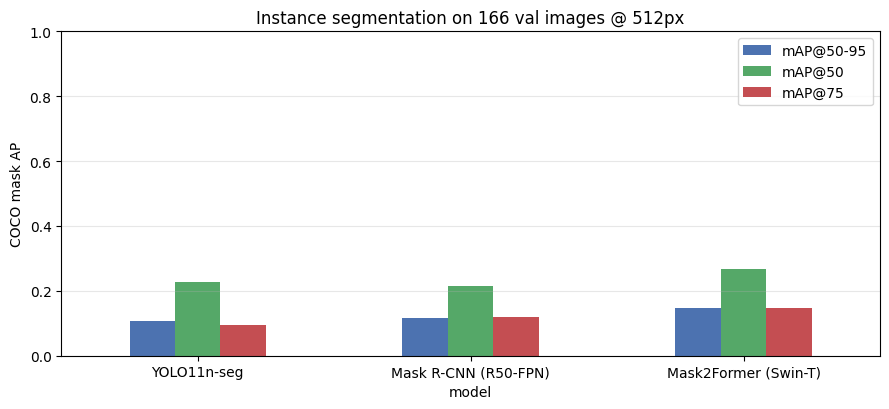

In [27]:
ax = METRICS[["mAP@50-95", "mAP@50", "mAP@75"]].plot.bar(figsize=(9, 4.2), rot=0,
                                                          color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_ylabel("COCO mask AP")
ax.set_ylim(0, 1)
ax.set_title(f"Instance segmentation on {len(EVAL_IMAGES)} {EVAL_SPLIT} images @ {IMG_SIZE}px")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_segm.png", dpi=150)
plt.show()

## 10. Side-by-side qualitative comparison

Same four validation images, same colours, one row per model.

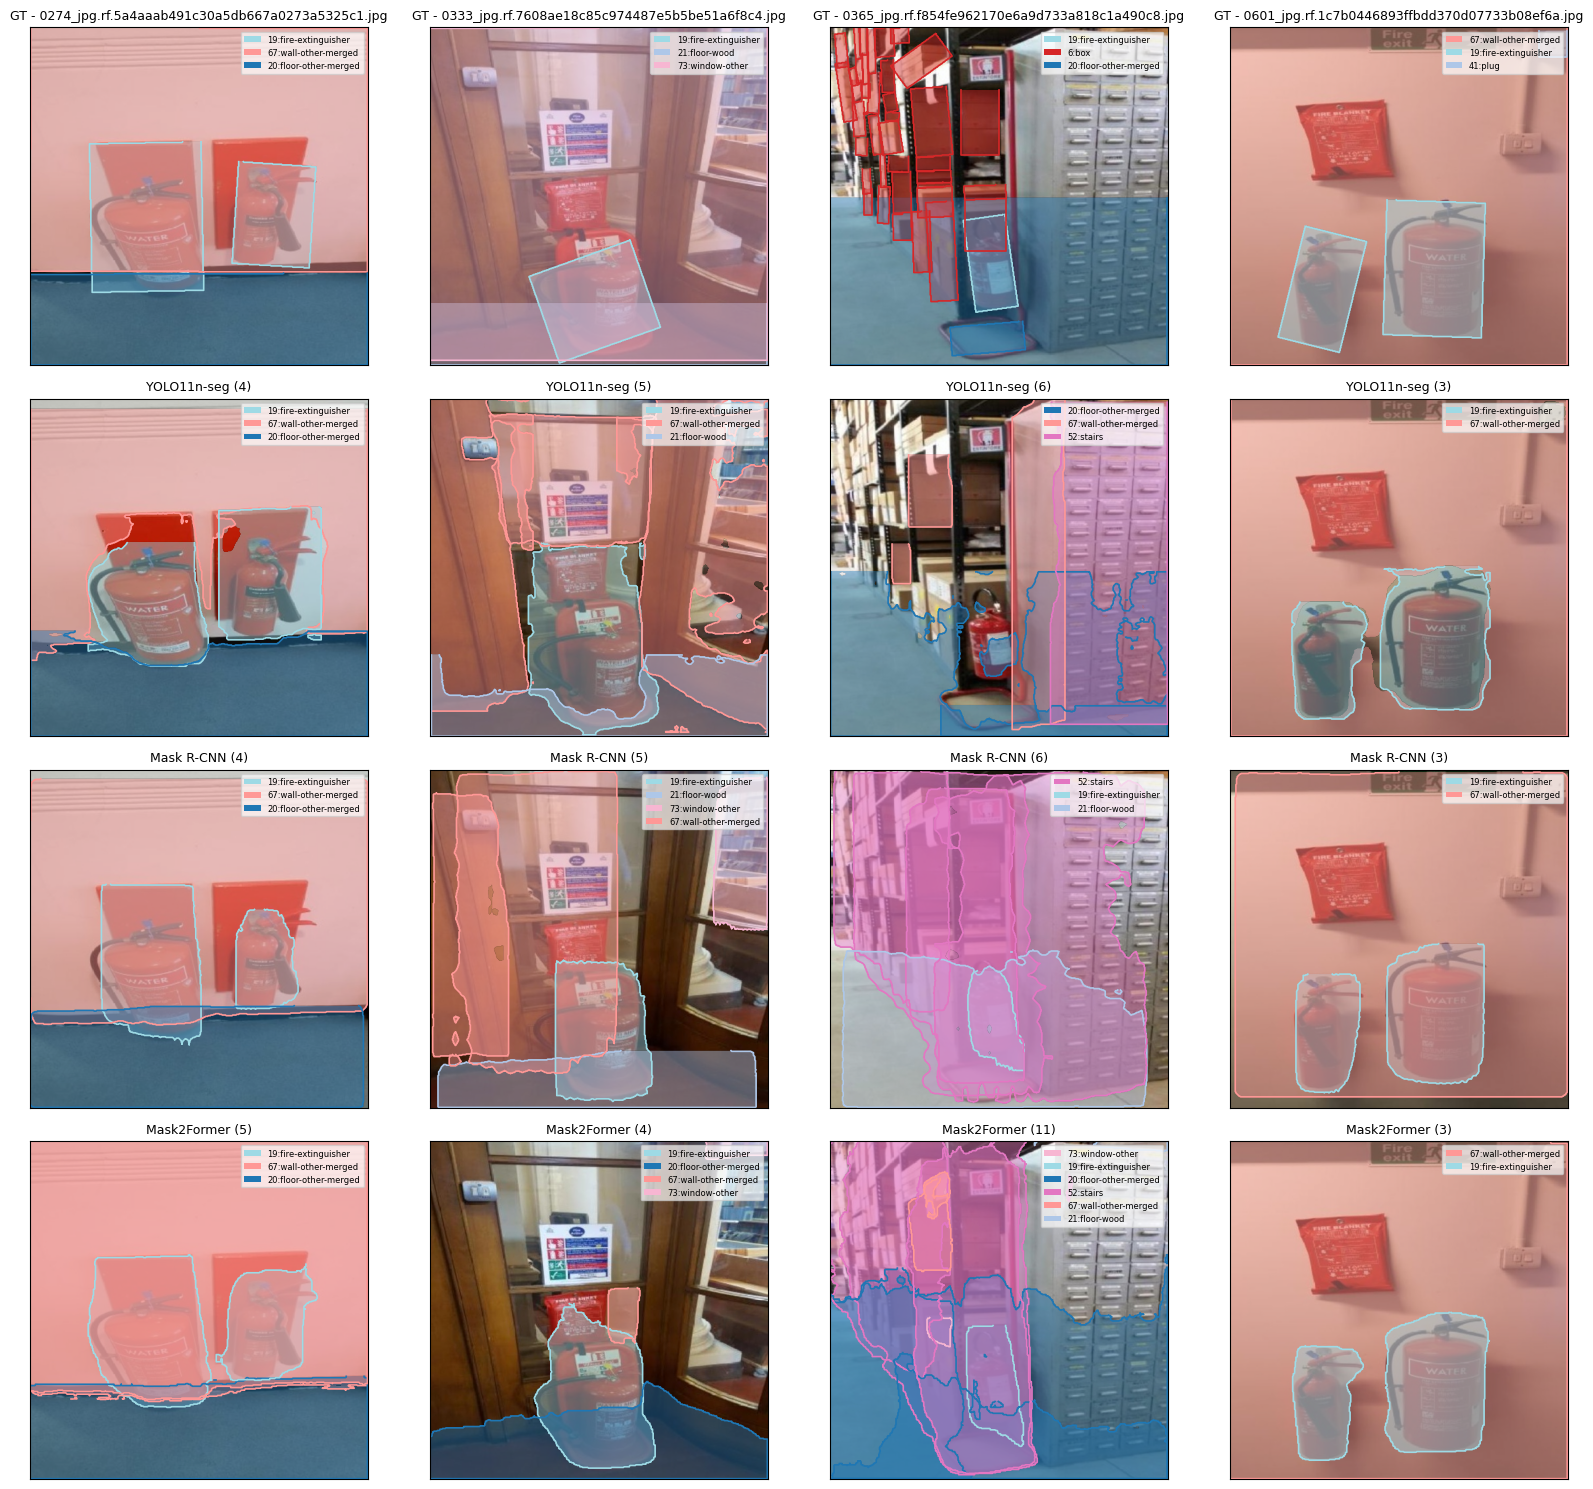

In [28]:
comp_imgs = VAL_IMAGES[:4]
m2f_comp = []
m2f_bs = BATCH_SIZE["mask2former"]
for i in range(0, len(comp_imgs), m2f_bs):
    m2f_comp += mask2former_predict(mask2former_eval, m2f_processor, comp_imgs[i:i + m2f_bs],
                                    score_thr=0.5, max_det=20)

comp_preds = {
    "YOLO11n-seg": yolo_predict(yolo_final, comp_imgs, conf=0.35, iou=0.6, max_det=20),
    "Mask R-CNN": maskrcnn_predict(maskrcnn_eval, comp_imgs, score_thr=0.5, max_det=20),
    "Mask2Former": m2f_comp,
}

fig, axes = plt.subplots(4, len(comp_imgs), figsize=(4.1 * len(comp_imgs), 15))
for j, p in enumerate(comp_imgs):
    img = load_rgb(p)
    gt_m, gt_l = masks_from_instances(read_labels(VAL_LABELS / f"{p.stem}.txt", IMG_SIZE, IMG_SIZE))
    draw_instances(axes[0, j], img, gt_m, gt_l, title=f"GT - {p.name}")
    for r, (name, preds) in enumerate(comp_preds.items(), start=1):
        d = preds[j]
        draw_instances(axes[r, j], img, d["masks"], d["labels"],
                       title=f"{name} ({len(d['masks'])})")
for ax in axes.ravel():
    if not ax.images:
        ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "comparison.png", dpi=140)
plt.show()

In [29]:
print("Summary\n" + "=" * 60)
for name, row in METRICS.iterrows():
    print(f"{name:<24s} mAP@50-95={row['mAP@50-95']:.3f}   mAP@50={row['mAP@50']:.3f}")
print("=" * 60)
best = METRICS["mAP@50-95"].idxmax()
print(f"Best mask AP@50-95: {best}")
print("\nOutputs:")
for p in [BEST_YOLO, MRCNN_DIR / "best.pt", M2F_DIR, OUT_DIR / "metrics_segm.csv"]:
    print(f"  {'OK ' if Path(p).exists() else 'MISSING'} {p}")

Summary
YOLO11n-seg              mAP@50-95=0.107   mAP@50=0.226
Mask R-CNN (R50-FPN)     mAP@50-95=0.117   mAP@50=0.216
Mask2Former (Swin-T)     mAP@50-95=0.149   mAP@50=0.266
Best mask AP@50-95: Mask2Former (Swin-T)

Outputs:
  OK  /content/outputs/yolo/yolo11n_seg_512/weights/best.pt
  OK  /content/outputs/maskrcnn/best.pt
  OK  /content/outputs/mask2former
  OK  /content/outputs/metrics_segm.csv
